# 🔥 D-Fire Detection: RF-DETR Small (512x512) with DoRA on Google Colab (Tesla T4)
## 5-Epoch Progressive Curriculum + Stochastic Blur Augmentation

This notebook is tailored and optimized for the **Google Colab NVIDIA Tesla T4 GPU (16 GB GDDR6)** (and local GPUs) with a **5-Epoch Progressive Curriculum Training Schedule** and **Stochastic Blur Augmentation**:
- **Progressive Curriculum Strategy:**
  - **Epochs 1 & 2 (Structural & Aerodynamic Phase):** 100% Grayscale ($R=G=B$). Forces the vision backbone and attention heads to learn smoke boundary turbulence, plume expansion, flame contours, and spatial context without color crutches.
  - **Epochs 3 & 4 (Bridging Transition Phase):** 50/50 Mixed Grayscale & Natural RGB. Stochastically alternates samples between grayscale and color, bridging structural representations with chromatic distributions.
  - **Epoch 5 (Full Color Real-World Fine-Tuning):** 100% Full 24-bit RGB Color. Adapts the final weights directly to natural optical camera feeds for real-world deployment.
- **Stochastic Blur Augmentation:** Random Gaussian blur ($p=0.3$, radius $0.5 - 2.5$) dynamically applied to training samples. Teaches self-attention heads to identify smoke density and flame cores even when camera feeds suffer from optical defocus, rain on lens, or rapid pan/tilt motion blur.
- **Hardware Optimization:** Uses Turing Tensor Cores (FP16 mixed precision) with optimal batch sizing for $512 \times 512$ inputs.
- **Architecture:** RF-DETR Small (`Roboflow/rf-detr-small`, native $512 \times 512$ resolution, 31.8M parameters).
- **PEFT Method:** **DoRA** (Weight-Decomposed Low-Rank Adaptation, Rank $r=16$, $\alpha=32$).
- **Custom Loss:** Categorical Focal Cross-Entropy + **Complete IoU (CIoU)** + L1 Bounding Box Loss.
- **Batch Configuration:** **Physical Batch = 8**, Gradient Accumulation = 4 $\rightarrow$ **Effective Batch = 32** (~4.5 GB VRAM used out of 16 GB on Colab T4 / 6 GB on GTX 1660 SUPER, leaving ample safety margin for Hungarian matching).
- **Data Pipeline:** 80/20 Stratified Split (17,221 train / 4,306 test), multi-core pre-caching to $512 \times 512$ RGB, and dynamic in-memory color/blur switching.
- **Safety:** Saves checkpoints per epoch (`rf_detr_small_dora_epoch_{epoch}.pt`, `best_rf_detr_small_dora.pt`) and mirrors directly to your **Google Drive** (`MyDrive/smoke_checkpoints/`).

### 1. GPU Check & Environment Setup
Verifies the Tesla T4 GPU (15.36 GB usable VRAM) and installs dependencies.

In [ ]:
# Verify NVIDIA Tesla T4 allocation
!nvidia-smi

# Fix: Remove Colab's outdated pre-installed torchao to prevent PEFT version conflict
!pip uninstall -y torchao

# Install required dependencies
!pip install -q torch torchvision transformers peft tqdm pillow scipy matplotlib requests

Thu Nov 12 11:44:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 2. (Optional) Mount Google Drive for Persistent Checkpoint Storage
Run this cell if you want checkpoints automatically mirrored to your Google Drive (`MyDrive/smoke_checkpoints/`).

In [ ]:
import os
SAVE_TO_DRIVE = True   # Set False if you only want local Colab storage

DRIVE_DIR = '/content/drive/MyDrive/smoke_checkpoints'
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        os.makedirs(DRIVE_DIR, exist_ok=True)
        print(f'Google Drive mounted! Checkpoints will mirror to: {DRIVE_DIR}')
    except Exception as e:
        print(f'Drive mount skipped ({e}). Checkpoints will save locally in ./checkpoints/')
        SAVE_TO_DRIVE = False

Mounted at /content/drive
Google Drive mounted! Checkpoints will mirror to: /content/drive/MyDrive/smoke_checkpoints


### 3. Download and Extract the D-Fire Dataset (~2.92 GB)
Streams the complete official D-Fire dataset directly from Hugging Face CDN (cloud-native, fast 100+ MB/s, zero 403 Forbidden issues), and automatically flattens subdirectories.

In [ ]:
import os
import shutil
import requests
import zipfile
from tqdm import tqdm

# High-speed Hugging Face CDN mirror of official D-Fire dataset archive
DATA_URL = 'https://huggingface.co/datasets/Stevebirth/fire-ulm-dfire/resolve/main/dfire_yolo_20261016.zip'
ZIP_PATH = 'dfire_dataset.zip'

# Check if valid dataset already exists in train/ and test/
has_train = os.path.exists('train/images') and len(os.listdir('train/images')) > 1000
has_test = os.path.exists('test/images') and len(os.listdir('test/images')) > 500

if not (has_train and has_test):
    # Clean up empty or corrupted directories from previous failed attempts
    if os.path.exists('train/images') and len(os.listdir('train/images')) < 1000:
        print('Purging empty train/test directories from prior failed attempt...')
        shutil.rmtree('train', ignore_errors=True)
        shutil.rmtree('test', ignore_errors=True)
        if os.path.exists('.stratified_done'): os.remove('.stratified_done')

    # 1. Purge any corrupted, partial, or 403 HTML error file from previous attempts
    if os.path.exists(ZIP_PATH):
        is_valid = False
        try:
            if zipfile.is_zipfile(ZIP_PATH) and os.path.getsize(ZIP_PATH) > 1_000_000_000:
                is_valid = True
        except Exception:
            is_valid = False

        if not is_valid:
            print(f'Purging invalid/corrupted archive from prior run: {ZIP_PATH} ({os.path.getsize(ZIP_PATH):,} bytes)...')
            os.remove(ZIP_PATH)
        else:
            print(f'Verified existing valid archive: {ZIP_PATH} ({os.path.getsize(ZIP_PATH)/(1024**3):.2f} GB)')

    # 2. Direct streaming chunked download from Hugging Face CDN
    if not os.path.exists(ZIP_PATH):
        print('Downloading official D-Fire dataset archive (~2.92 GB from Hugging Face CDN)...')
        headers = {'User-Agent': 'Mozilla/5.0'}
        with requests.get(DATA_URL, headers=headers, stream=True, allow_redirects=True) as resp:
            resp.raise_for_status()
            total_size = int(resp.headers.get('content-length', 0))
            with open(ZIP_PATH, 'wb') as f, tqdm(
                total=total_size,
                unit='iB',
                unit_scale=True,
                unit_divisor=1024,
                desc='Downloading D-Fire'
            ) as pbar:
                for chunk in resp.iter_content(chunk_size=4 * 1024 * 1024):
                    if chunk:
                        f.write(chunk)
                        pbar.update(len(chunk))
        print('Download finished successfully!')

    # 3. Extract the archive
    print('Extracting D-Fire dataset archive...')
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall('.')
    print('Extraction complete!')

    # 4. Flatten directory if extracted into a subfolder (e.g. dfire_yolo/)
    for candidate in ['dfire_yolo', 'D-Fire', 'dfire']:
        if os.path.exists(candidate) and os.path.isdir(candidate):
            print(f"Flattening extracted subfolder '{candidate}' to root...")
            for sub in os.listdir(candidate):
                src_sub = os.path.join(candidate, sub)
                dst_sub = os.path.join('.', sub)
                if os.path.exists(dst_sub):
                    shutil.rmtree(dst_sub) if os.path.isdir(dst_sub) else os.remove(dst_sub)
                shutil.move(src_sub, dst_sub)
            shutil.rmtree(candidate, ignore_errors=True)
else:
    print(f"Dataset already extracted and ready! Train: {len(os.listdir('train/images')):,} images, Test: {len(os.listdir('test/images')):,} images")

Download finished successfully!
Extracting D-Fire dataset archive...
Extraction complete!
Flattening extracted subfolder 'dfire_yolo' to root...


### 4. Verified 80/20 Stratified Train/Test Split
Guarantees exact 80/20 balance across all 4 strata (`smoke`, `fire`, `both`, and `none/background`).

In [ ]:
import shutil
import random
from collections import defaultdict

def get_stratum(lbl_path):
    if not os.path.exists(lbl_path) or os.path.getsize(lbl_path) == 0:
        return 'none'
    classes = set()
    with open(lbl_path, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split()
            if parts: classes.add(int(parts[0]))
    if not classes: return 'none'
    elif classes == {0}: return 'smoke'
    elif classes == {1}: return 'fire'
    elif classes == {0, 1}: return 'both'
    return f'other_{sorted(classes)}'

# Reset marker if train directory is empty from previous run
if os.path.exists('train/images') and len(os.listdir('train/images')) < 1000:
    if os.path.exists('.stratified_done'): os.remove('.stratified_done')

if not os.path.exists('.stratified_done'):
    print('Scanning dataset files across all extracted folders...')
    rng = random.Random(42)
    search_roots = ['.', 'dfire_yolo', 'D-Fire']
    samples = []
    for root in search_roots:
        for sp in ['train', 'test', 'val']:
            img_dir, lbl_dir = os.path.join(root, sp, 'images'), os.path.join(root, sp, 'labels')
            if not os.path.exists(img_dir): continue
            for f in os.listdir(img_dir):
                base, ext = os.path.splitext(f)
                if ext.lower() != '.jpg': continue
                lbl_file = os.path.join(lbl_dir, base + '.txt')
                if not os.path.exists(lbl_file): continue
                samples.append({'base': base, 'img': os.path.join(img_dir, f), 'lbl': lbl_file, 'stratum': get_stratum(lbl_file)})
        if len(samples) > 1000:
            break

    assert len(samples) > 1000, f'ERROR: Only found {len(samples)} images! Check dataset extraction in Cell 3.'
    print(f'Total valid samples collected: {len(samples):,}')

    strata = defaultdict(list)
    for s in samples: strata[s['stratum']].append(s)

    train_set, test_set = [], []
    for name, items in sorted(strata.items()):
        rng.shuffle(items)
        n_test = round(len(items) * 0.20)
        n_train = len(items) - n_test
        train_set.extend(items[:n_train])
        test_set.extend(items[n_train:])
        print(f"Stratum '{name}': Total={len(items):,} -> Train={n_train:,}, Test={n_test:,}")

    staging = '_split_staging'
    if os.path.exists(staging): shutil.rmtree(staging)
    for sp in ['train', 'test']:
        os.makedirs(os.path.join(staging, sp, 'images'), exist_ok=True)
        os.makedirs(os.path.join(staging, sp, 'labels'), exist_ok=True)

    for item in train_set:
        shutil.move(item['img'], os.path.join(staging, 'train', 'images', item['base'] + '.jpg'))
        shutil.move(item['lbl'], os.path.join(staging, 'train', 'labels', item['base'] + '.txt'))
    for item in test_set:
        shutil.move(item['img'], os.path.join(staging, 'test', 'images', item['base'] + '.jpg'))
        shutil.move(item['lbl'], os.path.join(staging, 'test', 'labels', item['base'] + '.txt'))

    for root in search_roots:
        for sp in ['train', 'test', 'val']:
            d = os.path.join(root, sp) if root != '.' else sp
            if os.path.exists(d): shutil.rmtree(d, ignore_errors=True)
        if root != '.' and os.path.exists(root): shutil.rmtree(root, ignore_errors=True)

    for sp in ['train', 'test']:
        shutil.move(os.path.join(staging, sp), sp)
    shutil.rmtree(staging)

    assert len(os.listdir('train/images')) > 10000, f"Train split check failed: {len(os.listdir('train/images'))}"
    assert len(os.listdir('test/images')) > 2000, f"Test split check failed: {len(os.listdir('test/images'))}"
    with open('.stratified_done', 'w') as f: f.write('done')
    print(f'\nStratified Split Done! Train: {len(train_set):,}, Test: {len(test_set):,}')
else:
    print(f"Stratified split already verified! Train: {len(os.listdir('train/images')):,}, Test: {len(os.listdir('test/images')):,}")

Scanning dataset files across all extracted folders...
Total valid samples collected: 21,527
Stratum 'both': Total=4,658 -> Train=3,726, Test=932
Stratum 'fire': Total=1,164 -> Train=931, Test=233
Stratum 'none': Total=9,838 -> Train=7,870, Test=1,968
Stratum 'smoke': Total=5,867 -> Train=4,694, Test=1,173

Stratified Split Done! Train: 17,221, Test: 4,306


### 5. Multi-Core Pre-Caching ($512 \times 512$ Full RGB Resolution)
Pre-resizes all images to native $512 \times 512$ as 24-bit RGB JPEGs in `images_512`. This enables instant in-memory color/grayscale transformation and on-the-fly stochastic blur augmentation without disk bottlenecks, supporting grayscale (Epochs 1-2), mixed (Epochs 3-4), and full color (Epoch 5).

In [ ]:
import time
from PIL import Image
from concurrent.futures import ProcessPoolExecutor

TARGET_SIZE = (512, 512)

def process_img(item):
    src, dst = item
    if os.path.exists(dst):
        try:
            with Image.open(dst) as test_im:
                if test_im.mode == 'RGB':
                    return
        except Exception:
            pass
    try:
        with Image.open(src) as im:
            rgb = im.convert('RGB').resize(TARGET_SIZE, Image.BILINEAR)
            rgb.save(dst, format='JPEG', quality=95)
    except Exception:
        pass

# Purge empty or corrupted cache directories if present
for split in ['train', 'test']:
    dst_dir = os.path.join(split, 'images_512')
    if os.path.exists(dst_dir) and len(os.listdir(dst_dir)) < 1000:
        print(f'Purging incomplete cache directory: {dst_dir}...')
        shutil.rmtree(dst_dir, ignore_errors=True)

for split in ['train', 'test']:
    src_dir = os.path.join(split, 'images')
    assert os.path.exists(src_dir), f'Directory {src_dir} does not exist!'
    dst_dir = os.path.join(split, 'images_512')
    os.makedirs(dst_dir, exist_ok=True)
    files = [f for f in os.listdir(src_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    assert len(files) > 1000, f'ERROR: {src_dir} contains only {len(files)} images!'
    tasks = [(os.path.join(src_dir, f), os.path.join(dst_dir, os.path.splitext(f)[0] + '.jpg')) for f in files]
    needed = [t for t in tasks if not os.path.exists(t[1])]
    if needed:
        print(f'[{split}] Pre-caching {len(needed):,} images to RGB (512x512)...')
        t0 = time.time()
        with ProcessPoolExecutor(max_workers=os.cpu_count() or 2) as executor:
            list(executor.map(process_img, needed, chunksize=100))
        print(f'[{split}] Completed in {time.time()-t0:.1f}s!')
    else:
        sample_check = os.path.join(dst_dir, os.path.splitext(files[0])[0] + '.jpg')
        with Image.open(sample_check) as s_im:
            if s_im.mode != 'RGB':
                print(f'[{split}] Upgrading existing cache to full 24-bit RGB (512x512)...')
                t0 = time.time()
                with ProcessPoolExecutor(max_workers=os.cpu_count() or 2) as executor:
                    list(executor.map(process_img, tasks, chunksize=100))
                print(f'[{split}] Upgrade completed in {time.time()-t0:.1f}s!')
            else:
                print(f'[{split}] Cache already verified at 512x512 RGB ({len(files):,} images).')

[train] Pre-caching 17,221 images to RGB (384x384)...
[train] Completed in 183.8s!
[test] Pre-caching 4,306 images to RGB (384x384)...
[test] Completed in 46.5s!


### 6. Dynamic Curriculum Dataset, Stochastic Blur Augmentation & CIoU Loss
`DFireDataset` dynamically supports:
- `'gray'`: 100% 3-channel grayscale ($R=G=B$)
- `'mixed'`: 50% grayscale / 50% natural RGB per sample
- `'color'`: 100% full 24-bit RGB color
- **Stochastic Blur Augmentation**: Random Gaussian blur ($p=0.3$, radius $0.5 - 2.5$) applied on-the-fly during training. Invariant to bounding box coordinates while enhancing model robustness against optical defocus and motion blur.

Includes coordinate sanitization ($w>0, h>0$, clamping $[0, 1]$), empty label handling for negative backgrounds, and persistent Hungarian matching with Complete IoU (CIoU) loss.

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.ops import complete_box_iou_loss, box_convert
from transformers.loss.loss_lw_detr import LwDetrImageLoss, LwDetrHungarianMatcher, _set_aux_loss
from PIL import Image, ImageFilter

class DFireDataset(Dataset):
    def __init__(self, root_dir, image_subdir='images_512', max_samples=None, color_mode='gray', blur_prob=0.3):
        """
        color_mode:
            'gray'  : 100% 3-channel grayscale (R=G=B)
            'mixed' : 50% grayscale / 50% natural RGB color (stochastic per sample)
            'color' : 100% full 24-bit natural RGB color
        blur_prob:
            Probability of applying random Gaussian blur (radius 0.5 - 2.5) for blur augmentation.
        """
        self.root_dir = root_dir
        self.img_dir = os.path.join(root_dir, image_subdir)
        if not os.path.exists(self.img_dir): self.img_dir = os.path.join(root_dir, 'images')
        self.lbl_dir = os.path.join(root_dir, 'labels')
        self.files = sorted([f for f in os.listdir(self.img_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
        if max_samples: self.files = self.files[:max_samples]
        self.color_mode = color_mode
        self.blur_prob = blur_prob

    def set_color_mode(self, mode):
        assert mode in ('gray', 'mixed', 'color'), f"Invalid color mode: {mode}"
        self.color_mode = mode

    def set_blur_prob(self, prob):
        self.blur_prob = max(0.0, min(1.0, prob))

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        fname = self.files[idx]
        base = os.path.splitext(fname)[0]
        with Image.open(os.path.join(self.img_dir, fname)) as im:
            rgb_im = im.convert('RGB')
            if self.color_mode == 'gray':
                img = rgb_im.convert('L').convert('RGB')
            elif self.color_mode == 'mixed':
                if random.random() < 0.5:
                    img = rgb_im.convert('L').convert('RGB')
                else:
                    img = rgb_im
            else: # 'color'
                img = rgb_im

            # Stochastic Random Blurring Augmentation
            if self.blur_prob > 0 and random.random() < self.blur_prob:
                radius = random.uniform(0.5, 2.5)
                img = img.filter(ImageFilter.GaussianBlur(radius=radius))

        boxes, classes = [], []
        lbl_path = os.path.join(self.lbl_dir, base + '.txt')
        if os.path.exists(lbl_path):
            with open(lbl_path, 'r', encoding='utf-8') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) == 5:
                        c, cx, cy, w, h = int(parts[0]), float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])
                        if w <= 1e-4 or h <= 1e-4: continue
                        boxes.append([max(0.0, min(1.0, cx)), max(0.0, min(1.0, cy)), max(1e-4, min(1.0, w)), max(1e-4, min(1.0, h))])
                        classes.append(c)

        if boxes:
            boxes_t = torch.tensor(boxes, dtype=torch.float32)
            classes_t = torch.tensor(classes, dtype=torch.long)
        else:
            boxes_t = torch.empty((0, 4), dtype=torch.float32)
            classes_t = torch.empty(0, dtype=torch.long)

        return img, {'class_labels': classes_t, 'boxes': boxes_t}

class DFireCollator:
    def __init__(self, processor):
        self.processor = processor
    def __call__(self, batch):
        images = [item[0] for item in batch]
        labels = [item[1] for item in batch]
        enc = self.processor(images=images, return_tensors='pt')
        return enc['pixel_values'], labels

class CustomCIoULoss(LwDetrImageLoss):
    def loss_boxes(self, outputs, targets, indices, num_boxes):
        idx = self._get_source_permutation_idx(indices)
        src_boxes = outputs['pred_boxes'][idx]
        tgt_boxes = torch.cat([t['boxes'][i] for t, (_, i) in zip(targets, indices)], dim=0)
        loss_bbox = nn.functional.l1_loss(src_boxes, tgt_boxes, reduction='none')
        losses = {'loss_bbox': loss_bbox.sum() / max(num_boxes, 1.0)}
        if src_boxes.numel() > 0:
            src_c = box_convert(src_boxes, in_fmt='cxcywh', out_fmt='xyxy')
            tgt_c = box_convert(tgt_boxes, in_fmt='cxcywh', out_fmt='xyxy')
            losses['loss_giou'] = complete_box_iou_loss(src_c, tgt_c, reduction='sum') / max(num_boxes, 1.0)
        else:
            losses['loss_giou'] = src_boxes.sum() * 0.0
        return losses

class PersistentDETRLoss(nn.Module):
    def __init__(self, config, device='cuda'):
        super().__init__()
        self.config = config
        self.device = device
        self.matcher = LwDetrHungarianMatcher(
            class_cost=config.class_cost,
            bbox_cost=config.bbox_cost,
            giou_cost=config.giou_cost
        )
        self.criterion = CustomCIoULoss(
            matcher=self.matcher,
            num_classes=config.num_labels,
            focal_alpha=config.focal_alpha,
            losses=['labels', 'boxes', 'cardinality'],
            group_detr=getattr(config, 'group_detr', 13)
        ).to(device)

        self.weight_dict = {
            'loss_ce': getattr(config, 'class_loss_coefficient', 1.0),
            'loss_bbox': getattr(config, 'bbox_loss_coefficient', 5.0),
            'loss_giou': getattr(config, 'giou_loss_coefficient', 2.0)
        }
        if getattr(config, 'auxiliary_loss', False):
            aux_weight_dict = {}
            for i in range(getattr(config, 'decoder_layers', 6) - 1):
                aux_weight_dict.update({k + f'_{i}': v for k, v in self.weight_dict.items()})
            self.weight_dict.update(aux_weight_dict)
        enc_weight_dict = {k + '_enc': v for k, v in self.weight_dict.items()}
        self.weight_dict.update(enc_weight_dict)

    def __call__(self, logits, labels, device, pred_boxes, config, outputs_class=None, outputs_coord=None, enc_outputs_class=None, enc_outputs_coord=None, **kwargs):
        outputs_loss = {
            'logits': logits,
            'pred_boxes': pred_boxes,
            'enc_outputs': {'logits': enc_outputs_class, 'pred_boxes': enc_outputs_coord}
        }
        auxiliary_outputs = None
        if config.auxiliary_loss and outputs_class is not None and outputs_coord is not None:
            auxiliary_outputs = _set_aux_loss(outputs_class, outputs_coord)
            outputs_loss['auxiliary_outputs'] = auxiliary_outputs
        loss_dict = self.criterion(outputs_loss, labels)
        loss = sum(loss_dict[k] * self.weight_dict[k] for k in loss_dict if k in self.weight_dict)
        return loss, loss_dict, auxiliary_outputs

### 7. Load RF-DETR Small ($512 \times 512$) & Apply DoRA (Rank $r=16, \alpha=32$)
Injects Weight-Decomposed Low-Rank Adaptation into the multi-head self-attention and cross-attention projection layers (`q_proj`, `v_proj`, `k_proj`, `o_proj`) of `Roboflow/rf-detr-small`.

In [ ]:
from transformers import AutoImageProcessor, AutoModelForObjectDetection
from peft import LoraConfig, get_peft_model

MODEL_ID = 'Roboflow/rf-detr-small'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Loading {MODEL_ID} on {device} ({torch.cuda.get_device_name(0)})...')

processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModelForObjectDetection.from_pretrained(MODEL_ID, num_labels=2, ignore_mismatched_sizes=True)
model.config.id2label = {0: 'smoke', 1: 'fire'}
model.config.label2id = {'smoke': 0, 'fire': 1}

# Persistent Custom Loss with Complete IoU (CIoU)
loss_module = PersistentDETRLoss(model.config, device=device)
model.loss_function = loss_module

# Inject DoRA Adapter
dora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=['q_proj', 'v_proj', 'k_proj', 'o_proj'],
    lora_dropout=0.05,
    bias='none',
    use_dora=True
)
model.model.backbone = get_peft_model(model.model.backbone, dora_config)
model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f'DoRA Model Ready: {trainable:,} Trainable / {total:,} Total ({trainable/total*100:.2f}%)')

Loading model on cuda (Tesla T4)...


preprocessor_config.json:   0%|          | 0.00/442 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.77k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `91`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  122MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/465 [00:00<?, ?it/s]

[transformers] RfDetrForObjectDetection LOAD REPORT from: Roboflow/rf-detr-nano
Key                                       | Status   |                                                                                        
------------------------------------------+----------+----------------------------------------------------------------------------------------
model.enc_out_class_embed.{0...12}.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([91]) vs model:torch.Size([2])          
model.enc_out_class_embed.{0...12}.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([91, 256]) vs model:torch.Size([2, 256])
class_embed.bias                          | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([91]) vs model:torch.Size([2])          
class_embed.weight                        | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([91, 256]) vs model:torch.Size([2, 256])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not

DoRA Model Ready: 7,489,284 Trainable / 30,755,332 Total (24.35%)


### 8. 5-Epoch Progressive Curriculum Training with Stochastic Blurring on Tesla T4
**Curriculum Schedule:**
- **Epoch 1 & 2:** **100% Grayscale + Random Blur** (`curriculum_mode = 'gray'`) — Forces attention heads to learn geometric structure, edge boundaries, and smoke turbulence without color shortcuts.
- **Epoch 3 & 4:** **50/50 Mixed + Random Blur** (`curriculum_mode = 'mixed'`) — Stochastically mixes grayscale and natural RGB, smoothly bridging structural representations with chromatic distributions.
- **Epoch 5:** **100% Full Color + Random Blur** (`curriculum_mode = 'color'`) — Fine-tunes directly on 24-bit natural RGB photography with blur tolerance for real-world optical camera deployment.

**Hardware Optimization:** Physical Batch = 8 $\times$ Grad Accum = 4 $\rightarrow$ **Effective Batch = 32** (~4.5 GB VRAM consumed at $512 \times 512$ resolution, well within 16 GB on Tesla T4 or 6 GB on GTX 1660 SUPER).

In [ ]:
import math

PHYSICAL_BATCH = 8       # Optimal for 512x512 on Tesla T4 / GTX 1660 SUPER
GRAD_ACCUM = 4           # Effective Batch Size = 32 (8 * 4)
EPOCHS = 5               # 5-Epoch Curriculum Schedule
NUM_WORKERS = min(2, os.cpu_count() or 2) # Colab 2 vCPUs

LOCAL_CHECKPOINT_DIR = 'checkpoints'
os.makedirs(LOCAL_CHECKPOINT_DIR, exist_ok=True)

torch.backends.cudnn.benchmark = True

train_ds = DFireDataset('train', image_subdir='images_512', color_mode='gray', blur_prob=0.3)
val_ds = DFireDataset('test', image_subdir='images_512', max_samples=500, color_mode='color', blur_prob=0.0)
collator = DFireCollator(processor)

assert len(train_ds) > 1000, f'ERROR: train_ds has only {len(train_ds)} samples! Check images_512 directory.'
assert len(val_ds) > 100, f'ERROR: val_ds has only {len(val_ds)} samples! Check images_512 directory.'
print(f'Datasets Loaded & Verified: {len(train_ds):,} train samples, {len(val_ds):,} validation samples.')

def create_train_loader(dataset):
    return DataLoader(
        dataset,
        batch_size=PHYSICAL_BATCH,
        shuffle=True,
        num_workers=NUM_WORKERS,
        collate_fn=collator,
        pin_memory=True,
        persistent_workers=False
    )

train_loader = create_train_loader(train_ds)
val_loader = DataLoader(
    val_ds,
    batch_size=PHYSICAL_BATCH,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collator,
    pin_memory=True
)

# Differential Learning Rates (AdamW + Cosine Decay)
dora_params = [p for n, p in model.named_parameters() if 'lora_' in n and p.requires_grad]
head_params = [p for n, p in model.named_parameters() if 'lora_' not in n and p.requires_grad]

optimizer = torch.optim.AdamW([
    {'params': dora_params, 'lr': 1e-4, 'weight_decay': 1e-4},
    {'params': head_params, 'lr': 2e-4, 'weight_decay': 1e-4}
])

total_opt_steps = (len(train_loader) // GRAD_ACCUM) * EPOCHS
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_opt_steps, eta_min=1e-6)
scaler = torch.amp.GradScaler('cuda')

print(f"\n--- Training Configuration ---")
print(f"- Architecture: Roboflow/rf-detr-small (512x512 Native)")
print(f"- Augmentation: Stochastic Gaussian Blur (p=0.3, radius 0.5-2.5)")
print(f"- Train Samples: {len(train_ds):,} | Val Samples: {len(val_ds):,}")
print(f"- Batching: Physical Batch {PHYSICAL_BATCH} x Grad Accum {GRAD_ACCUM} = Effective Batch {PHYSICAL_BATCH * GRAD_ACCUM}")
print(f"- Optimizer Updates: {total_opt_steps:,} total across {EPOCHS} epochs\n")

best_val = float('inf')

for epoch in range(1, EPOCHS + 1):
    # Progressive 5-Epoch Curriculum Schedule
    if epoch in (1, 2):
        curriculum_mode = 'gray'
        curriculum_banner = "PHASE 1: 100% GRAYSCALE (Geometric Structure & Smoke Turbulence)"
    elif epoch in (3, 4):
        curriculum_mode = 'mixed'
        curriculum_banner = "PHASE 2: 50/50 MIXED (Grayscale + Natural RGB Color Transition)"
    else: # epoch == 5
        curriculum_mode = 'color'
        curriculum_banner = "PHASE 3: 100% FULL RGB COLOR (Natural Sensor Adaptation)"

    train_ds.set_color_mode(curriculum_mode)
    train_loader = create_train_loader(train_ds)

    model.train()
    running_loss = 0.0
    t_epoch = time.time()
    optimizer.zero_grad(set_to_none=True)

    print(f"\n==================== Epoch [{epoch}/{EPOCHS}] ====================")
    print(f"--> Curriculum Mode: [{curriculum_mode.upper()}] - {curriculum_banner}")
    print(f"--> Stochastic Blur Augmentation: Active (p=0.3)")
    print(f"--> Learning Rate: {optimizer.param_groups[0]['lr']:.2e}\n")

    for step, (pixels, targets) in enumerate(train_loader, start=1):
        t0 = time.time()
        pixels = pixels.to(device, non_blocking=True)
        targets = [{k: v.to(device, non_blocking=True) for k, v in t.items()} for t in targets]

        with torch.amp.autocast('cuda', dtype=torch.float16):
            outputs = model(pixel_values=pixels, labels=targets)
            loss = outputs.loss / GRAD_ACCUM

        scaler.scale(loss).backward()

        if step % GRAD_ACCUM == 0 or step == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(filter(lambda p: p.requires_grad, model.parameters()), max_norm=0.1)
            scale_prev = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            if scale_prev <= scaler.get_scale(): scheduler.step()

        step_time = time.time() - t0
        loss_val = (loss * GRAD_ACCUM).item()
        running_loss += loss_val

        if step % 50 == 0 or step == len(train_loader):
            current_lr = optimizer.param_groups[0]['lr']
            eta = ((len(train_loader) - step) * step_time) / 60
            fps = PHYSICAL_BATCH / max(step_time, 1e-4)
            ce = outputs.loss_dict.get('loss_ce', torch.tensor(0.0)).item()
            ciou = outputs.loss_dict.get('loss_giou', torch.tensor(0.0)).item()
            print(f"Ep [{epoch}/{EPOCHS}][{curriculum_mode[0].upper()}] Step [{step:>4}/{len(train_loader)}] Loss: {loss_val:.4f} (CE: {ce:.3f}, CIoU: {ciou:.3f}) | LR: {current_lr:.2e} | Speed: {step_time:.2f}s ({fps:.1f} img/s) | ETA: {eta:.1f}m")

    print(f'\nEpoch {epoch} finished in {(time.time()-t_epoch)/60:.1f} mins. Avg Train Loss: {running_loss/len(train_loader):.4f}')

    # Validation Pass (Tested on Natural RGB Color Benchmark)
    model.eval()
    v_loss, v_ce, v_ciou = 0.0, 0.0, 0.0
    with torch.no_grad():
        for pixels, targets in val_loader:
            pixels = pixels.to(device, non_blocking=True)
            targets = [{k: v.to(device, non_blocking=True) for k, v in t.items()} for t in targets]
            with torch.amp.autocast('cuda', dtype=torch.float16):
                outputs = model(pixel_values=pixels, labels=targets)
            v_loss += outputs.loss.item()
            v_ce += outputs.loss_dict.get('loss_ce', torch.tensor(0.0)).item()
            v_ciou += outputs.loss_dict.get('loss_giou', torch.tensor(0.0)).item()

    avg_val = v_loss / max(len(val_loader), 1)
    print(f"Validation Loss (Full Color Test Set): {avg_val:.4f} (Val CE: {v_ce/len(val_loader):.4f}, Val CIoU: {v_ciou/len(val_loader):.4f})")

    # Save per-epoch checkpoints and mirror to Google Drive
    ckpt = {
        'epoch': epoch,
        'curriculum_mode': curriculum_mode,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'val_loss': avg_val
    }
    torch.save(ckpt, f'{LOCAL_CHECKPOINT_DIR}/rf_detr_small_dora_epoch_{epoch}.pt')
    torch.save(ckpt, f'{LOCAL_CHECKPOINT_DIR}/checkpoint_last.pt')
    if 'SAVE_TO_DRIVE' in globals() and SAVE_TO_DRIVE:
        torch.save(ckpt, f'{DRIVE_DIR}/rf_detr_small_dora_epoch_{epoch}.pt')
        torch.save(ckpt, f'{DRIVE_DIR}/checkpoint_last.pt')

    if avg_val < best_val:
        best_val = avg_val
        torch.save(ckpt, f'{LOCAL_CHECKPOINT_DIR}/best_rf_detr_small_dora.pt')
        if 'SAVE_TO_DRIVE' in globals() and SAVE_TO_DRIVE:
            torch.save(ckpt, f'{DRIVE_DIR}/best_rf_detr_small_dora.pt')
        print(f'--> [NEW BEST] Saved best model (Val Loss: {best_val:.4f})')

print('\nAll 5 epochs of progressive curriculum training with blur augmentation completed successfully!')

Datasets Loaded & Verified: 17,221 train samples, 500 validation samples.
Starting 5-Epoch Progressive Curriculum Training on Tesla T4:
- Train samples: 17,221 | Steps per epoch: 1,077
- Physical Batch: 16 x Grad Accum 2 = Effective Batch 32
- Optimizer Updates: 2,693 total across 5 epochs


==================== Epoch [1/5] ====================
--> Curriculum Mode: [GRAY] - PHASE 1: 100% GRAYSCALE (Geometric Structure & Smoke Turbulence)
--> Learning Rate: 0.00e+00

Ep [1/5][G] Step [  50/1077] Loss: 77.1536 (CE: 0.672, CIoU: 0.683) | LR: 9.00e-06 | Speed: 0.71s (22.4 img/s) | ETA: 12.2m
Ep [1/5][G] Step [ 100/1077] Loss: 88.7975 (CE: 0.789, CIoU: 0.584) | LR: 2.15e-05 | Speed: 0.73s (22.0 img/s) | ETA: 11.9m
Ep [1/5][G] Step [ 150/1077] Loss: 63.5314 (CE: 0.795, CIoU: 0.589) | LR: 3.40e-05 | Speed: 0.73s (22.0 img/s) | ETA: 11.2m
Ep [1/5][G] Step [ 200/1077] Loss: 31.1124 (CE: 0.714, CIoU: 0.649) | LR: 4.60e-05 | Speed: 0.72s (22.3 img/s) | ETA: 10.5m
Ep [1/5][G] Step [ 250/1077] Loss

### 9. Visual Inference on Test Samples (Full RGB Color at $512 \times 512$)
Visualizes smoke and fire predictions on natural color test images with bounding boxes, confidence scores, and class labels using the trained `best_rf_detr_small_dora.pt`.

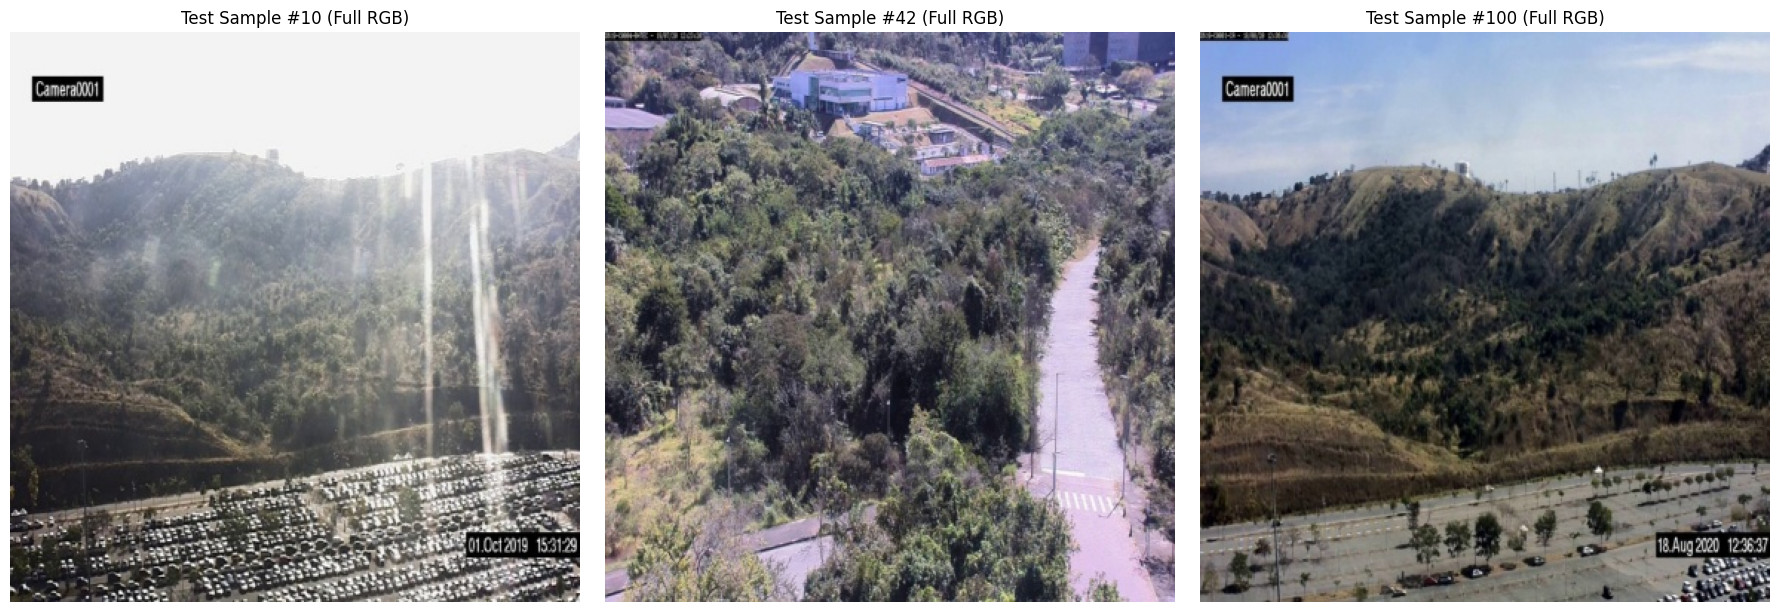

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

best_ckpt = torch.load(f'{LOCAL_CHECKPOINT_DIR}/best_rf_detr_small_dora.pt', map_location=device)
model.load_state_dict(best_ckpt['model_state_dict'])
model.eval()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
test_ds = DFireDataset('test', image_subdir='images_512', color_mode='color', blur_prob=0.0)

id2name = {0: 'smoke', 1: 'fire'}
color_map = {'smoke': 'cyan', 'fire': 'red'}

for idx, sample_idx in enumerate([10, 42, 100]):
    img, target = test_ds[sample_idx]
    enc = processor(images=[img], return_tensors='pt')
    with torch.no_grad():
        with torch.amp.autocast('cuda', dtype=torch.float16):
            outputs = model(pixel_values=enc['pixel_values'].to(device))

    ax = axes[idx]
    ax.imshow(img)
    ax.set_title(f'Test Sample #{sample_idx} (Full RGB 512x512)')
    ax.axis('off')

    logits = outputs.logits[0].sigmoid()
    boxes = outputs.pred_boxes[0]
    scores, labels = logits.max(dim=-1)
    keep = scores > 0.35

    w_img, h_img = img.size
    for score, label, box in zip(scores[keep], labels[keep], boxes[keep]):
        cx, cy, w, h = box.tolist()
        x0 = (cx - w/2) * w_img
        y0 = (cy - h/2) * h_img
        bw = w * w_img
        bh = h * h_img
        cls_name = id2name[label.item()]
        rect = patches.Rectangle((x0, y0), bw, bh, linewidth=2, edgecolor=color_map[cls_name], facecolor='none')
        ax.add_patch(rect)
        ax.text(x0, max(0, y0 - 5), f'{cls_name}: {score:.2f}', color=color_map[cls_name], fontsize=10, weight='bold', bbox=dict(facecolor='black', alpha=0.5, pad=1))

plt.tight_layout()
plt.show()